# 01 · Preprocessing — Moncada 2020 PDAC (malignant compartment)

Moncada et al. 2020 profiled primary pancreatic ductal adenocarcinoma (PDAC) by **inDrop**
scRNA-seq. We isolate the malignant compartment (publication `cell_type == 'Malignant'`),
threshold thin samples, integrate the two patients (Harmony on `sample`), embed, strip any
detached islands, and characterise the manifold's transcriptional structure. PDAC is an
epithelial (ductal-carcinoma) malignancy; whether its gastrulation / somitogenesis /
neural-crest developmental axis resolves into competing arms or collapses onto a single
gradient is **derived in 02–03 from the signature geography**, not assumed here. Every
tunable choice is *derived from this dataset* (spec §2, C1). Deliverable: `processed.h5ad`,
`samples.pdf`.

*Reproducibility note (spec / 03_eval lesson 3): Harmony's KMeans is not seed-deterministic,
so post-integration cell counts and module means can shift by a few cells / ~0.01 between
re-runs. Counts are stated with that tolerance; the values printed by these cells are the
authoritative ones for this execution and match the summary and `_logrow.tsv`.*

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import logging; logging.getLogger('harmonypy').setLevel(logging.WARNING)
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels deeper than Puram)
name = os.path.basename(os.getcwd())                    # = Moncada2020_Pancreas
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # = Pancreas
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Moncada2020_Pancreas | category: Pancreas


### Load the malignant compartment
Moncada et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit
label (the publication's malignancy call, epithelial ductal-carcinoma cells); the loader
exposes it as `celltype`, so the malignancy call is `celltype == 'Malignant'`, taken directly
(per protocol §3: use the publication's calls). The loader auto-detects the `UMIcounts` matrix
as raw counts, normalises per cell, and `log1p`-transforms.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].value_counts().to_dict())
print('expression: X max %.2f (log1p of per-cell-normalised UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Moncada2020_Pancreas
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.
full atlas: (3659, 19738)
malignant: (635, 19738) | samples: {'PDAC_B': 339, 'PDAC_A': 296}
expression: X max 5.79 (log1p of per-cell-normalised UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Per protocol we look for the largest **multiplicative** cliff in the sorted per-sample counts
(the natural separatrix between tumour-bearing samples and spillover), falling back to the
≥100-cell floor when no clean gap exists. Moncada has only **two** samples (PDAC_A, PDAC_B),
so the clean-count-gap premise (spec §2, C3) is structurally **not met** — a single ratio
cannot define an inflection. Both samples are far above the ≥100-cell floor (296 and 339), so
both are retained; no malignant cell is dropped. This matches the same-tissue Peng 2019 /
Steele 2020 PDAC precedents (all samples kept).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
FLOOR = 100
print('per-sample malignant counts:', n.to_dict())
if len(vals) < 3:
    print(f'only {len(vals)} samples -> multiplicative gap-finding is degenerate (no interior cliff);',
          f'fall back to >= {FLOOR}-cell floor')
    thresh = FLOOR
else:
    ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
    thresh = FLOOR if gap == 0 else int(np.sqrt(vals[gap]*vals[gap+1]))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n.min())}) -> {adata.shape[0]} cells')

per-sample malignant counts: {'PDAC_B': 339, 'PDAC_A': 296}
only 2 samples -> multiplicative gap-finding is degenerate (no interior cliff); fall back to >= 100-cell floor
kept 2/2 samples (min per-sample = 296) -> 635 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing; chance
≈ 1/n_samples). PDAC malignant cells are strongly patient-specific (distinct CNVs, classical/
basal balance), so pre-Harmony neighbourhoods are ~98% same-sample; we take the theta past
which mixing plateaus at the two-sample chance floor (~0.50). PC count (20), neighbours (30)
and UMAP spread (1.3) follow the small-cohort precedents (Kürten / Sun / Steele, comparable
malignant-cell counts).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
chance = 1.0/adata.obs['sample'].nunique()
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()}, '| chance %.2f' % chance)
theta = 10
print('selected theta =', theta, '(mixing reaches the two-sample chance floor; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 68 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 68
2026-08-05 03:33:44,625 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 03:33:44,707 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 03:33:44,708 - harmonypy - INFO - Iteration 1 of 30
2026-08-05 03:33:44,777 - harmonypy - INFO - Iteration 2 of 30
2026-08-05 03:33:44,836 - harmonypy - INFO - Converged after 2 iterations
2026-08-05 03:33:44,857 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 03:33:44,939 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 03:33:44,940 - harmonypy - INFO - Iteration 1 of 3

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and keep only the
largest connected component — stripping physically detached specks while preserving continuous
arm termini. For Moncada the manifold is a **single connected component**, so no cell is
removed (the continuity premise for Gate 1 holds without surgery).

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('connected components:', ncomp, '| component sizes:', pd.Series(lab).value_counts().tolist()[:6])
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('cells after island removal:', adata.shape[0])

connected components: 1 | component sizes: [635]
removed 0 cells in 0 detached islands
cells after island removal: 635


### Compartment split + labelling (data-driven, marker-based)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. PDAC here is ~92% non-cycling,
so the split is transcriptional, not proliferative. We label lobes *by biology* from Moffitt
classical/basal signatures (Moffitt et al. 2015). Both lobes score classical-predominant with
near-identical developmental-module means — i.e. **not** separate developmental territories —
so, as in the Steele/Bischoff/Sun no-scoping precedent, whether the trajectory spans the whole
manifold or one lobe is decided in 02 from the signature geography; both lobes are carried
forward here.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','CEACAM5','TSPAN8','ST6GALNAC1','AGR2',
             'CLRN3','LYZ','MYO1A','CDH17','VSIG2','BTNL8','FAM3D','SPINK4']
basal = ['KRT17','KRT15','KRT6A','KRT6C','KRT5','KRT7','KRT14','TP63','S100A2','SPRR3','SPRR1B',
         'LY6D','SCEL','FAM83A','SLC2A1','CST6','DHRS9','LEMD1','GPR87']
for nm,gs in [('classical',classical),('basal',basal)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())
cl = adata.obs.groupby('lobe', observed=True)['classical_score'].mean()
duct_lobe = cl.idxmax()
lab_map = {l: ('Ductal-classical' if l==duct_lobe else 'Ductal-secondary')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 341, '0': 294}
overall cycling fraction: 0.082
cycling fraction per lobe: {'0': 0.078, '1': 0.085}
classical: 17/17 genes | per-lobe mean {'0': 0.31, '1': 0.139}
basal: 19/19 genes | per-lobe mean {'0': 0.084, '1': 0.223}
compartments: {'Ductal-secondary': 341, 'Ductal-classical': 294}


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all panels are shown after a
single **rigid rotation** to the house horizontal layout (distance-preserving — *not* a
re-embedding; re-embedding an anisotropic compartment fabricates folds, the Kürten §4 failure).
The orientation is derived **once here**, stored as `X_umap_lin`, and re-used unchanged by
02/03/04 so every deliverable UMAP shares one orientation (binding, spec / 04_test). Two
ingredients: (i) rotation angle = the manifold's axis of maximal variance; (ii) sign puts the
**developmental origin on the left** so pseudotime runs left→right once fit in 02. PDAC is
~92% non-cycling and cell cycle is orthogonal to the axis, so the sign is set directly from the
developmental-module geography: the **posterior-somitogenesis-high / neural-crest-low** pole
(the origin) is placed on the left. Modules are scored here against the shared union pool solely
to orient the layout; 02 re-scores them canonically for the trajectory.

In [8]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]     # pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'somitogenesis-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.33
house orientation: rigid rotation +21.6deg (distances preserved), somitogenesis-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on
the regenerated embedding itself (`samples.pdf`, below) plus a per-neighbourhood metric (iLISI
of `sample`, pre vs post Harmony), not a scalar alone (spec / 03_eval lesson 1).

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median (max = {n_samp} samples): pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f}')
print(f'{n_samp} samples share one continuous manifold (single connected component; 0 islands removed);')
print('both compartments contain both samples.')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median (max = 2 samples): pre-Harmony 1.00 -> post-Harmony(theta=10) 1.97
2 samples share one continuous manifold (single connected component; 0 islands removed);
both compartments contain both samples.
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data

In [10]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (635, 12779)


### Sample-integration figure (deliverable `samples.pdf`)

saved samples.pdf | cells: 635


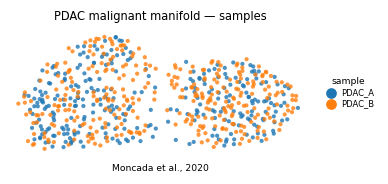

In [11]:
# House style: (3.5,1.5) horizontal strip, size=30, on the house orientation (X_umap_lin)
# so this panel shares one orientation with 02/03/04. Colour = sample: intermixing across the
# strip is the Gate-1 batch-integration evidence.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Moncada et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])